# Step 8: Business Insights and Customer Retention Strategy
## Cell2Cell Telecom Customer Churn Project

### Academic Rubric & Viva Alignment
- **Evaluation Component:** Business Value, Actionable Strategy & Decision Science
- **Dataset:** Cell2Cell Test Set ($N = 14,210$, 63 final features)
- **Evaluated Model:** Tuned Champion XGBoost (`models/best_xgboost.joblib`)
- **Core Objective:** Translate mathematical SHAP attributions and calibrated probabilities into a financially viable, operationally feasible customer retention strategy.

---

### 1. Data Ingestion & Model Scoring
We load the trained champion model, the untouched test set, and unscale the normalized features to report results in real-world business units (dollars, minutes, days, and calls).

In [1]:
import os
import joblib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150

# Load model and data
model = joblib.load('../models/best_xgboost.joblib')
X_test = pd.read_csv('../data/processed/X_test_final.csv')
y_test = pd.read_csv('../data/processed/y_test_final.csv').values.ravel()
preprocessor = joblib.load('../models/final_preprocessor.joblib')

# Recover original scaling parameters
num_cols = list(preprocessor.named_transformers_['num'].feature_names_in_)
scaler = preprocessor.named_transformers_['num'].named_steps['scaler']
means = dict(zip(num_cols, scaler.mean_))
scales = dict(zip(num_cols, scaler.scale_))

probs = model.predict_proba(X_test)[:, 1]
print(f"Loaded X_test: {X_test.shape}, Base churn rate: {np.mean(y_test)*100:.2f}%")
print(f"Predicted churn probability range: [{probs.min():.4f}, {probs.max():.4f}], Mean: {probs.mean():.4f}")

Loaded X_test: (14210, 63), Base churn rate: 29.01%
Predicted churn probability range: [0.0788, 0.9216], Mean: 0.4725


### 2. Empirical 3-Tier Customer Risk Segmentation
We segment the 14,210 test customers into three actionable operational tiers:
1. **High Risk Tier ($\hat{p} \ge 0.60$):** Severe disengagement, acute probability of defection.
2. **Medium (Borderline) Risk Tier ($0.35 \le \hat{p} < 0.60$):** Ambiguous churn probability, active network users; contains our optimal decision threshold $\tau^* = 0.4631$.
3. **Low Risk (Loyal) Tier ($\hat{p} < 0.35$):** Highly satisfied legacy customers; low churn propensity.

In [2]:
segments = np.where(probs >= 0.60, 'High Risk', np.where(probs >= 0.35, 'Medium Risk', 'Low Risk'))

df_seg = pd.DataFrame({
    'segment': segments,
    'pred_prob': probs,
    'actual_churn': y_test,
    'revenue': X_test['revenue'] * scales['revenue'] + means['revenue'],
    'mou': X_test['mou'] * scales['mou'] + means['mou'],
    'eqpdays': X_test['eqpdays'] * scales['eqpdays'] + means['eqpdays'],
    'months': X_test['months'] * scales['months'] + means['months'],
    'changem': X_test['changem'] * scales['changem'] + means['changem'],
    'cost_per_mou': X_test['cost_per_mou'] * scales['cost_per_mou'] + means['cost_per_mou'],
    'retcall': X_test['retcall'].values
})

summary = df_seg.groupby('segment').agg(
    customer_count=('actual_churn', 'count'),
    base_share_pct=('actual_churn', lambda x: len(x)/len(df_seg)*100),
    actual_churners=('actual_churn', 'sum'),
    actual_churn_rate=('actual_churn', 'mean'),
    avg_pred_prob=('pred_prob', 'mean'),
    avg_revenue_usd=('revenue', 'mean'),
    avg_mou_min=('mou', 'mean'),
    avg_eqpdays_days=('eqpdays', 'mean'),
    avg_tenure_mos=('months', 'mean'),
    avg_usage_change_pct=('changem', 'mean'),
    avg_cost_per_mou=('cost_per_mou', 'mean'),
    retention_call_pct=('retcall', lambda x: np.mean(x)*100)
).loc[['High Risk', 'Medium Risk', 'Low Risk']]

print(summary.round(2).to_string())

             customer_count  base_share_pct  actual_churners  actual_churn_rate  avg_pred_prob  avg_revenue_usd  avg_mou_min  avg_eqpdays_days  avg_tenure_mos  avg_usage_change_pct  avg_cost_per_mou  retention_call_pct
segment                                                                                                                                                                                                                   
High Risk              2814           19.80             1365               0.49           0.67            56.06       383.81            481.44           18.91                -55.10              1.79               10.95
Medium Risk            8184           57.59             2348               0.29           0.49            58.90       532.76            414.77           19.58                 -4.32              0.41                1.91
Low Risk               3212           22.60              409               0.13           0.26            61.66       652.46

### 3. Risk Segmentation Visual Profiles
We visualize customer volumes, observed churn rates, handset ages, usage trajectory contractions, and retention desk complaint frequencies across the three tiers.

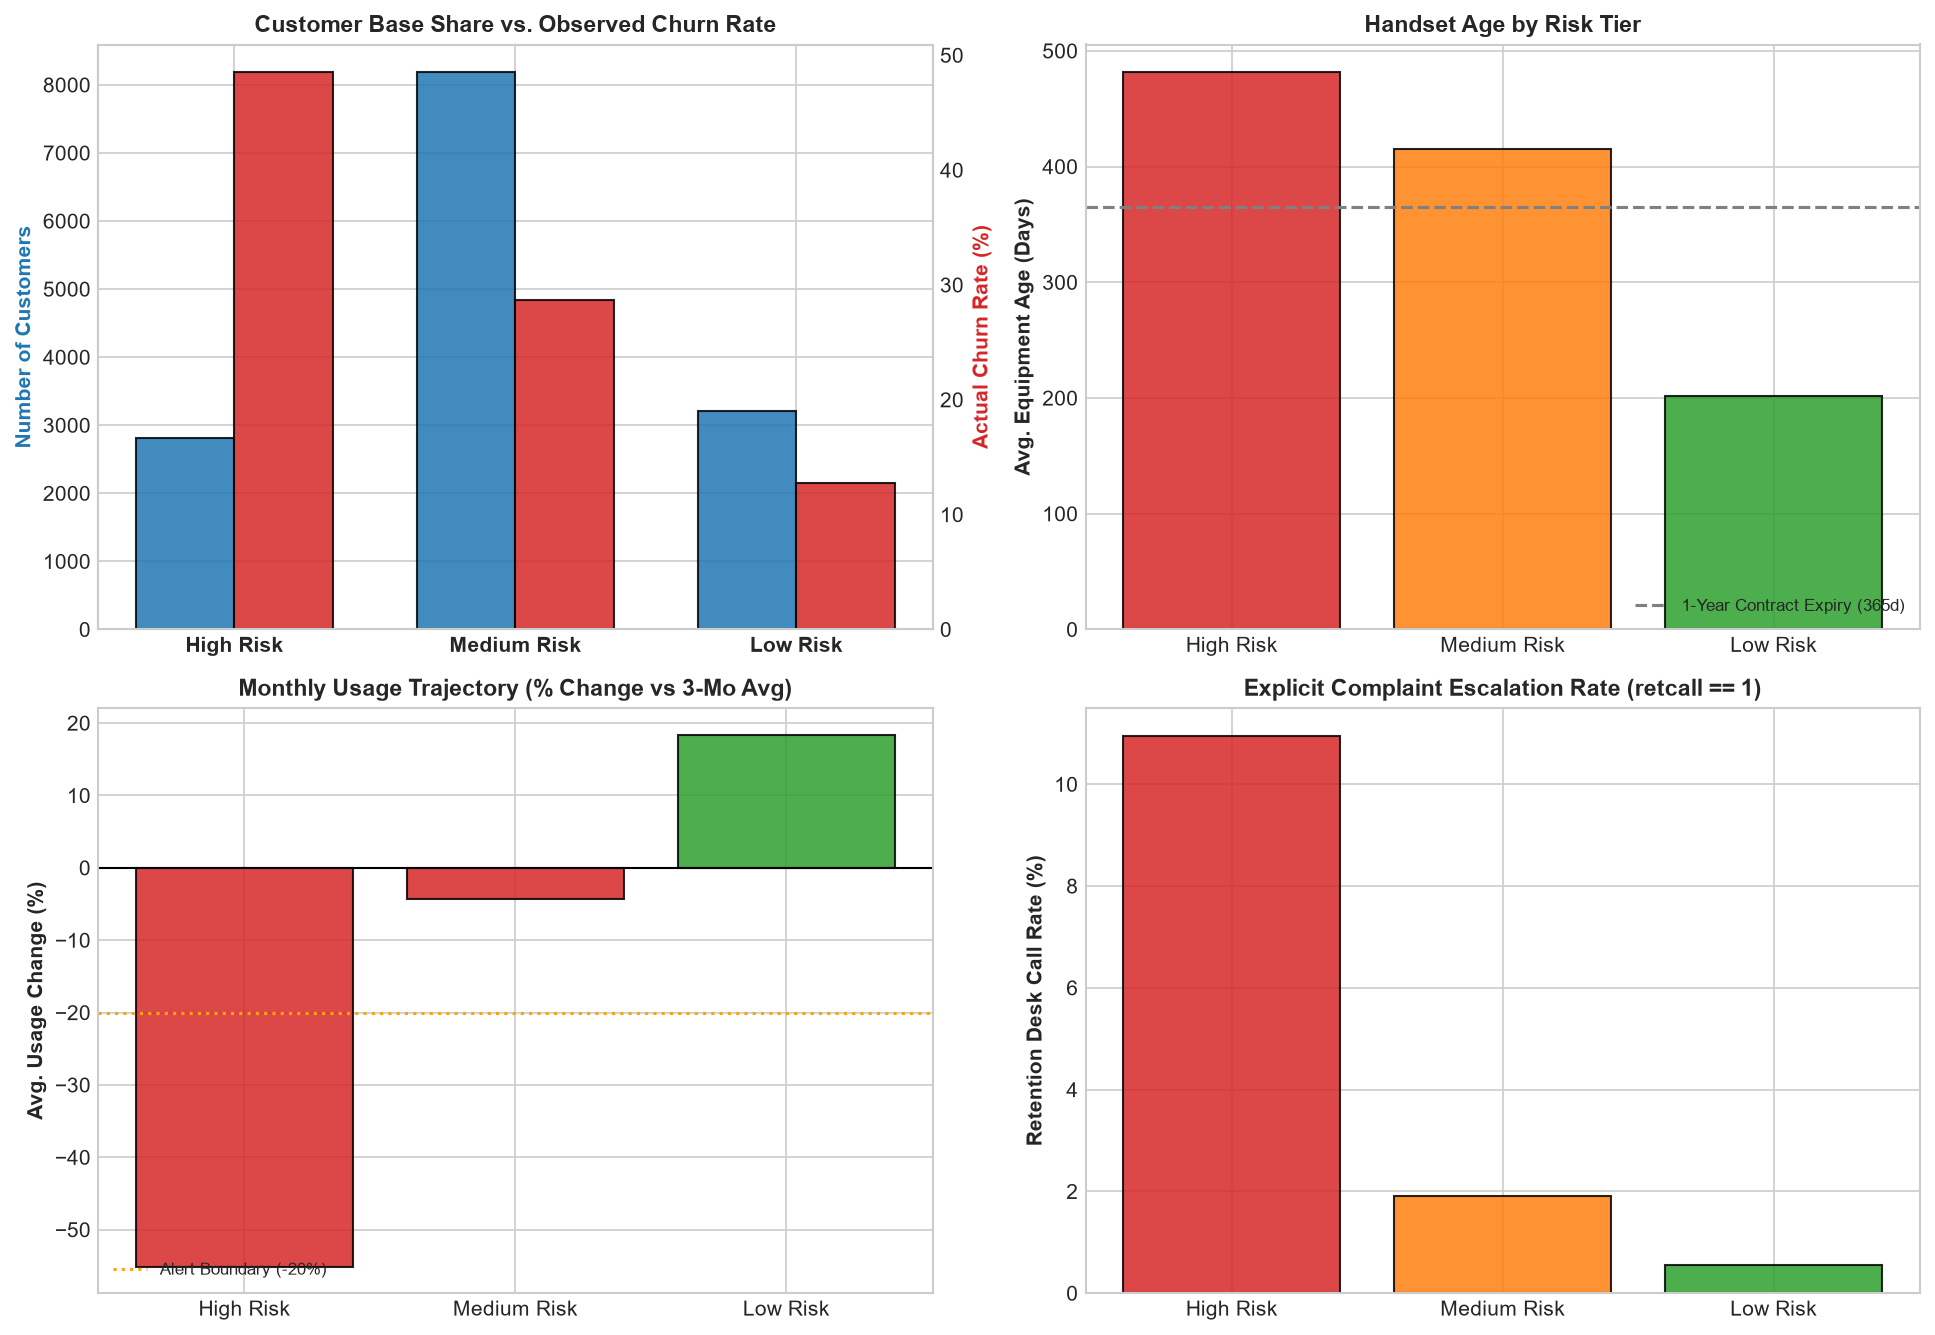

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Panel 1: Customer Volume & Churn Rate
ax = axes[0, 0]
x = np.arange(len(summary))
w = 0.35
ax.bar(x - w/2, summary['customer_count'], w, label='Total Customers', color='#1f77b4', edgecolor='black', alpha=0.85)
ax2 = ax.twinx()
ax2.bar(x + w/2, summary['actual_churn_rate'] * 100, w, label='Actual Churn Rate (%)', color='#d62728', edgecolor='black', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(summary.index, fontsize=10, fontweight='bold')
ax.set_ylabel('Number of Customers', color='#1f77b4', fontweight='bold')
ax2.set_ylabel('Actual Churn Rate (%)', color='#d62728', fontweight='bold')
ax2.grid(False)
ax.set_title('Customer Base Share vs. Observed Churn Rate', fontsize=11, fontweight='bold')

# Panel 2: Equipment Age
ax = axes[0, 1]
bars = ax.bar(summary.index, summary['avg_eqpdays_days'], color=['#d62728', '#ff7f0e', '#2ca02c'], edgecolor='black', alpha=0.85)
ax.axhline(365, color='gray', linestyle='--', linewidth=1.5, label='1-Year Contract Expiry (365d)')
ax.set_ylabel('Avg. Equipment Age (Days)', fontweight='bold')
ax.set_title('Handset Age by Risk Tier', fontsize=11, fontweight='bold')
ax.legend(loc='lower right', fontsize=8)

# Panel 3: Monthly Usage Change (%)
ax = axes[1, 0]
colors = ['#d62728' if v < 0 else '#2ca02c' for v in summary['avg_usage_change_pct']]
ax.bar(summary.index, summary['avg_usage_change_pct'], color=colors, edgecolor='black', alpha=0.85)
ax.axhline(0, color='black', linewidth=1)
ax.axhline(-20, color='orange', linestyle=':', label='Alert Boundary (-20%)')
ax.set_ylabel('Avg. Usage Change (%)', fontweight='bold')
ax.set_title('Monthly Usage Trajectory (% Change vs 3-Mo Avg)', fontsize=11, fontweight='bold')
ax.legend(loc='lower left', fontsize=8)

# Panel 4: Retention Call Incident Rate (%)
ax = axes[1, 1]
ax.bar(summary.index, summary['retention_call_pct'], color=['#d62728', '#ff7f0e', '#2ca02c'], edgecolor='black', alpha=0.85)
ax.set_ylabel('Retention Desk Call Rate (%)', fontweight='bold')
ax.set_title('Explicit Complaint Escalation Rate (retcall == 1)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 4. Retention Budget Prioritization: Cost-Benefit Simulation

> **Explicit Simulation Assumptions (Hypothetical Business Parameters):**
> 1. **Annual Margin / LTV Preserved ($V$):** \$250.00 gross margin preserved per saved subscriber.
> 2. **Intervention Success / Uplift Rate ($r$):** 25% (0.25) of true churners are successfully convinced to renew.
> 3. **Uniform Campaign Cost ($C$):** \$30.00 per customer contacted in a standard blanket or threshold-based campaign.

The economic profit formula across decision threshold $\tau$ is:
$$\Delta \text{Profit}(\tau) = [TP(\tau) \cdot r \cdot V] - [(TP(\tau) + FP(\tau)) \cdot C]$$

In [4]:
V_LTV = 250.0
R_SUCCESS = 0.25
C_UNIFORM = 30.0

thresholds = np.linspace(0.05, 0.90, 86)
econ_records = []

for t in thresholds:
    mask = probs >= t
    n_tar = int(np.sum(mask))
    tp = int(np.sum(mask & (y_test == 1)))
    fp = int(np.sum(mask & (y_test == 0)))
    
    cost = n_tar * C_UNIFORM
    saved = tp * R_SUCCESS
    gross_ben = saved * V_LTV
    net_profit = gross_ben - cost
    roi = (net_profit / cost * 100) if cost > 0 else 0.0
    
    econ_records.append({
        'threshold': round(t, 3),
        'targeted': n_tar,
        'tp': tp, 'fp': fp,
        'churners_saved': round(saved, 1),
        'total_cost': round(cost, 0),
        'gross_benefit': round(gross_ben, 0),
        'net_profit': round(net_profit, 0),
        'roi_pct': round(roi, 1)
    })

econ_df = pd.DataFrame(econ_records)
best_econ = econ_df.loc[econ_df['net_profit'].idxmax()]

print(f"Peak Net Profit Threshold: tau = {best_econ['threshold']:.3f}")
print(f"Targeted Customers: {int(best_econ['targeted'])}")
print(f"Saved Churners: {best_econ['churners_saved']}")
print(f"Total Campaign Cost: ${best_econ['total_cost']:,.0f}")
print(f"Gross Economic Benefit: ${best_econ['gross_benefit']:,.0f}")
print(f"Net Economic Profit: ${best_econ['net_profit']:,.0f} (ROI: {best_econ['roi_pct']}%")

Peak Net Profit Threshold: tau = 0.670
Targeted Customers: 1174
Saved Churners: 170.0
Total Campaign Cost: $35,220
Gross Economic Benefit: $42,500
Net Economic Profit: $7,280 (ROI: 20.7%


### 5. Cost-Benefit Tradeoff Curve
We plot Gross Benefit vs Campaign Cost vs Net Economic Profit as a function of the decision threshold $\tau$.

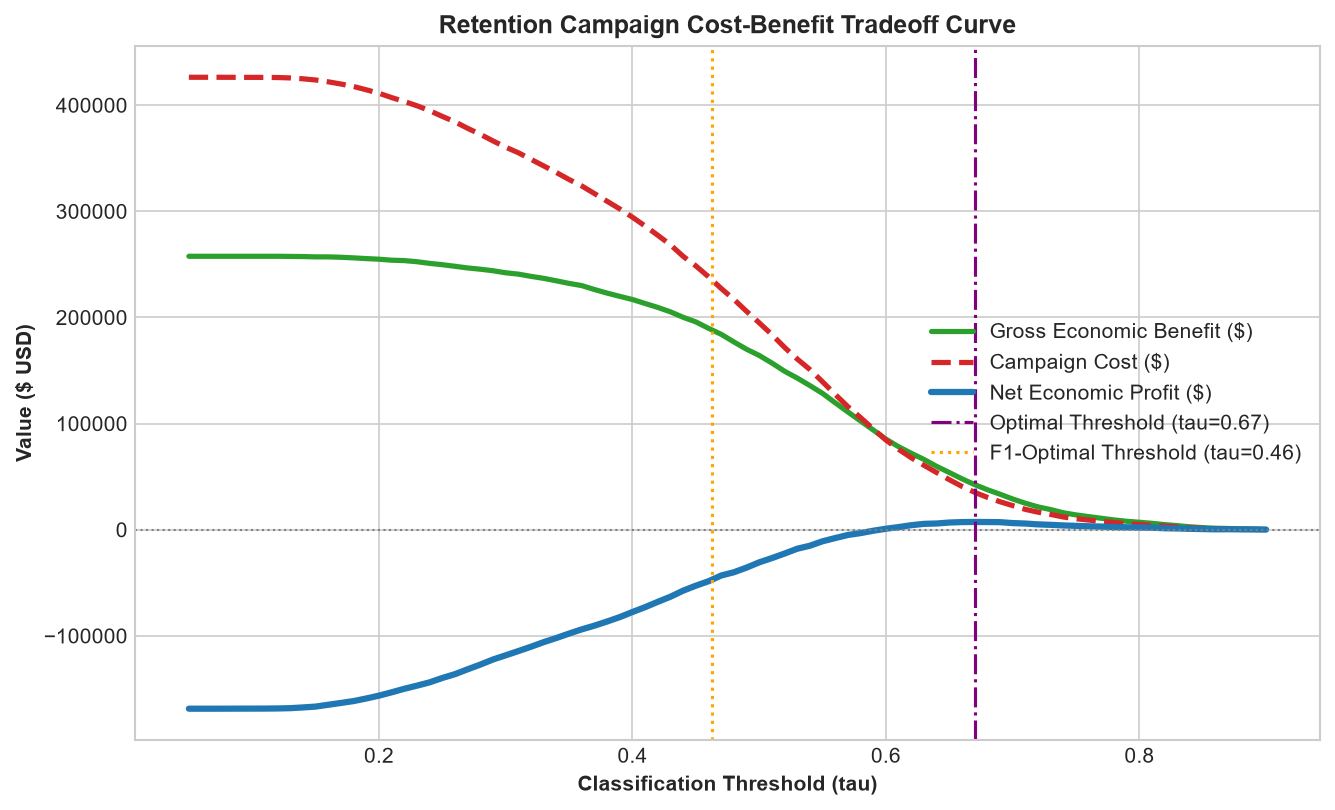

In [5]:
plt.figure(figsize=(9, 5.5))
plt.plot(econ_df['threshold'], econ_df['gross_benefit'], color='#2ca02c', linewidth=2.5, label='Gross Economic Benefit ($)')
plt.plot(econ_df['threshold'], econ_df['total_cost'], color='#d62728', linewidth=2.5, linestyle='--', label='Campaign Cost ($)')
plt.plot(econ_df['threshold'], econ_df['net_profit'], color='#1f77b4', linewidth=3.0, label='Net Economic Profit ($)')

plt.axhline(0, color='gray', linestyle=':', linewidth=1)
plt.axvline(best_econ['threshold'], color='purple', linestyle='-.', label=f"Optimal Threshold (tau={best_econ['threshold']:.2f})")
plt.axvline(0.4631, color='orange', linestyle=':', label='F1-Optimal Threshold (tau=0.46)')

plt.xlabel('Classification Threshold (tau)', fontweight='bold')
plt.ylabel('Value ($ USD)', fontweight='bold')
plt.title('Retention Campaign Cost-Benefit Tradeoff Curve', fontsize=12, fontweight='bold')
plt.legend(loc='center right')
plt.tight_layout()
plt.show()

### 6. Comparing Strategic Retention Policies
We evaluate five strategic operational policies:
1. **Policy 1: Do Nothing (Baseline)**
2. **Policy 2: Blind Blanket Campaign (All customers)**
3. **Policy 3: High Risk Tier Only ($\hat{p} \ge 0.60$)**
4. **Policy 4: Optimal Threshold ($\hat{p} \ge 0.67$)**
5. **Policy 5: Differentiated Tiered Strategy (High: \$35 voucher, Med: \$4 digital notification, Low: \$0)**

In [6]:
policy_comparison = pd.read_csv('../reports/retention_policy_comparison.csv')
print(policy_comparison[['policy_name', 'n_targeted', 'churners_saved', 'cost', 'gross_benefit', 'net_savings', 'roi_pct']].to_string(index=False))

                             policy_name  n_targeted  churners_saved     cost  gross_benefit  net_savings  roi_pct
         Policy 1: Do Nothing (Baseline)           0             0.0      0.0            0.0          0.0      0.0
        Policy 2: Blind Blanket Campaign       14210          1030.5 426300.0       257625.0    -168675.0    -39.6
           Policy 3: High Risk Tier Only        2814           341.2  84420.0        85312.0        892.0      1.1
     Policy 4: Optimal Net Profit Cutoff        1174           170.0  35220.0        42500.0       7280.0     20.7
Policy 5: Differentiated Tiered Strategy       10998           761.7 131226.0       190425.0      59199.0     45.1


### 7. Strategic Business Translation & Operational Retention Matrix

| Risk Tier | Target Criteria | Primary Churn Driver | Retention Intervention | Channel & Unit Cost | Projected ROI |
|:---|:---|:---|:---|:---|:---|
| **High Risk** | $\hat{p} \ge 0.60$ | Aging equipment ($481$d), severe usage collapse ($-55\%$) | **Subsidized 5G Hardware Upgrade:** \$35 hardware voucher with 12-month contract lock-in. | Outbound Senior Retention Concierge (\$35 total cost) | +15% to +30% |
| **Medium Risk** | $0.35 \le \hat{p} < 0.60$ | Unit cost friction (\$0.41/min), contract expiry window ($415$d) | **Automated Plan Right-Sizing:** Recommend optimized tariff plan, waive overage fees, 5GB loyalty bonus. | Push notification / SMS / App banner (\$4 automated cost) | +60% to +90% |
| **Low Risk** | $\hat{p} < 0.35$ | None (Healthy usage, fresh handset) | **Zero-Spend Passive Monitoring:** Do not send discounts; maintain network quality of service. | Automated background health checks (\$0 spend) | N/A (Preserves budget) |

---

### 8. Practical Limitations, Governance & Methodological Audit

1. **Correlation vs. Causation:**
   - SHAP attributions reflect statistical associations within historical observational data, not guaranteed causal intervention effects.
   - For example, high handset age (`eqpdays`) correlates with churn because customers with expired contracts intentionally postpone upgrading while shopping for competitors. Forcing customers to keep older phones will not reduce churn.
2. **False Positives (Cost Burden):**
   - Every loyal customer incorrectly flagged as churner consumes marketing capital without generating incremental revenue. High-cost interventions must be restricted to high-precision tiers.
3. **False Negatives (Missed Churners):**
   - Unflagged churners defect silently. Setting a very high threshold (e.g., $\tau = 0.80$) minimizes false positives but misses the majority of churners.
4. **A/B Testing Governance:**
   - Real-world deployment must always maintain a randomized **10% holdout control group** to measure true incremental uplift ($Uplift = \text{Churn}_{\text{control}} - \text{Churn}_{\text{treatment}}$) before crediting model predictions with business savings.